In [ ]:
import sys, neo4j, pandas
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from scipy.sparse import csr_matrix
from neo4j import GraphDatabase
print(sys.version)
print(neo4j.__version__)

3.10.22 (main, Oct  9 2026, 15:18:58) [MSC v.1944 64 bit (AMD64)]
6.4.1


#SETUP KODE

In [ ]:

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "PASSWORD")  # ganti sementara dengan password asli
DB = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def run(q, **params):
    with driver.session(database=DB) as s:
        return s.run(q, **params).data()

print("Terhubung")

Terhubung


### 2.1 Wrangling dan EDA 

In [ ]:
#1.Menentukan periode waktu
P1_START, P1_END = "2015-05-12", "2015-06-26"   
P2_START, P2_END = "2015-07-06", "2015-08-10"   

Deskripsi
- P1 (training): 2015-05-12 s.d. sebelum 2015-06-26
- P2 (testing): 2015-07-06 s.d. sebelum 2015-08-10

In [8]:
#2. Filter timestamp
df = pd.read_csv("data/events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")   # UTC

def ambil_periode(df, start, end):
    return df[(df["datetime"] >= start) & (df["datetime"] < end)].copy()

p1 = ambil_periode(df, P1_START, P1_END)
p2 = ambil_periode(df, P2_START, P2_END)

p1.drop(columns="datetime").to_csv("data/events_p1.csv", index=False)
p2.drop(columns="datetime").to_csv("data/events_p2.csv", index=False)

print("P1:", p1.shape, "| P2:", p2.shape)
print("Visitor di P1 dan P2:", len(set(p1.visitorid) & set(p2.visitorid)))

P1: (940430, 6) | P2: (762421, 6)
Visitor di P1 dan P2: 16174


In [9]:
#3.Subgraph
df_nodes = pd.DataFrame(run("""MATCH (n) RETURN labels(n)[0] AS jenis_simpul, 
                            count(*) AS jumlah ORDER BY jumlah DESC"""))
print(df_nodes)
df_rels = pd.DataFrame(run("""MATCH (a)-[r]->(b)
                            RETURN labels(a)[0] AS dari, type(r) AS relasi, 
                            labels(b)[0] AS ke, count(*) AS jumlah
                            ORDER BY jumlah DESC
                            """))
print(df_rels)
print("Total relasi:", df_rels["jumlah"].sum())

  jenis_simpul  jumlah
0      Visitor  479153
1         Item  145405
      dari         relasi    ke  jumlah
0  Visitor         VIEWED  Item  909730
1  Visitor  ADDED_TO_CART  Item   23038
2  Visitor         BOUGHT  Item    7662
Total relasi: 940430


# Analisis No. 3: Komposisi Subgraph
**Hasil komposisi simpul**
| Jenis simpul | Jumlah |
|---|---|
| Visitor (User) | 479.153 |
| Item | 145.405 |
**Hasil komposisi relasi**
| Dari | Relasi | Ke | Jumlah |
|---|---|---|---|
| Visitor | VIEWED | Item | 909.730 |
| Visitor | ADDED_TO_CART | Item | 23.038 |
| Visitor | BOUGHT | Item | 7.662 |
Total relasi = 940.430, sama dengan jumlah baris `events_p1.csv`. Artinya
setiap baris interaksi menjadi tepat satu relasi, sehingga impor berhasil dan tidak ada duplikasi.
Query simpul:
`MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah ORDER BY jumlah DESC`
- `MATCH (n)` mencocokkan semua simpul di graf tanpa syarat label.
- `labels(n)[0]` mengambil label pertama dari simpul, yaitu `Visitor` atau `Item`.
  `labels()` mengembalikan list, jadi diambil elemen indeks 0.
- `count(*)` menghitung jumlah baris pada tiap kelompok. Cypher tidak memakai
  `GROUP BY` seperti SQL: kolom non-agregat di `RETURN` (di sini `labels(n)[0]`)
  otomatis menjadi kunci pengelompokan.
- `ORDER BY jumlah DESC` mengurutkan hasil dari jumlah terbesar.
Query relasi:
`MATCH (a)-[r]->(b) RETURN labels(a)[0] AS dari, type(r) AS relasi, labels(b)[0] AS ke, count(*) AS jumlah ORDER BY jumlah DESC`
- `(a)-[r]->(b)` adalah pola relasi berarah: simpul `a` terhubung ke simpul `b`
  lewat relasi `r`. Arah panah penting, jadi hanya relasi dari Visitor ke Item
  yang cocok.
- `type(r)` mengembalikan jenis relasi: `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`.
- `labels(a)[0]` dan `labels(b)[0]` menunjukkan jenis simpul di ujung awal dan akhir relasi.
- `count(*)` dan `ORDER BY` bekerja sama seperti pada query simpul.
So subgraph bersifat bipartit dengan dua jenis simpul (Visitor dan Item)
dan tiga jenis relasi dari Visitor ke Item. Mayoritas interaksi adalah `VIEWED`
(sekitar 96,7%), sedangkan `ADDED_TO_CART` (sekitar 2,4%) dan `BOUGHT` (sekitar 0,8%)
jauh lebih sedikit. Karena itu bobot interaksi pada VSM (view=1, addtocart=3,
transaction=5) dipakai agar interaksi yang lebih kuat bernilai lebih besar.

In [11]:
#4.VSM untuk simpul User (Visitor), bobot : (view=1, addtocart=3, transaction=5)
p1 = pd.read_csv("data/events_p1.csv")
bobot = {"view": 1, "addtocart": 3, "transaction": 5}
p1["w"] = p1["event"].map(bobot)
# agregasi bobot per (visitor, item)
agg = p1.groupby(["visitorid", "itemid"], as_index=False)["w"].sum()
users = agg["visitorid"].astype("category")
items = agg["itemid"].astype("category")
X_user = csr_matrix(
    (agg["w"].values, (users.cat.codes, items.cat.codes)),
    shape=(users.cat.categories.size, items.cat.categories.size),)
print("Shape (user x item):", X_user.shape)
print("Dimensi vektor user (jumlah item):", X_user.shape[1])
print("Entri non-nol:", X_user.nnz)
print("Density:", X_user.nnz / (X_user.shape[0] * X_user.shape[1]))
nnz_per_user = np.diff(X_user.indptr)
print("Item per user -> rata-rata:", nnz_per_user.mean(), "| median:", np.median(nnz_per_user), "| maks:", nnz_per_user.max())


Shape (user x item): (479153, 145405)
Dimensi vektor user (jumlah item): 145405
Entri non-nol: 726123
Density: 1.0422133717162307e-05
Item per user -> rata-rata: 1.5154303531439852 | median: 1.0 | maks: 1201


# Analisis no. 4
Karakteristik VSM User
- Setiap Visitor dipetakan menjadi vektor berdimensi 145.405 (satu dimensi per Item).
- Shape matriks User x Item = (479.153, 145.405); bobot: view=1, addtocart=3, transaction=5.
- Matriks sangat sparse: 726.123 entri non-nol, density 1,04e-5.
- Rata-rata 1,52 item per user (median 1); maksimum 1.201 (outlier/bot).
- Dense butuh ratusan GB, maka disimpan sebagai CSR.
- Plot networkx adalah sampel 15 user teraktif dan 40 item terpopuler; graf bipartit.
- Konsekuensi: banyak user hanya punya 1 item, sehingga vektornya hampir tidak punya
  irisan dengan user lain, dan similarity antar-user kebanyakan 0.

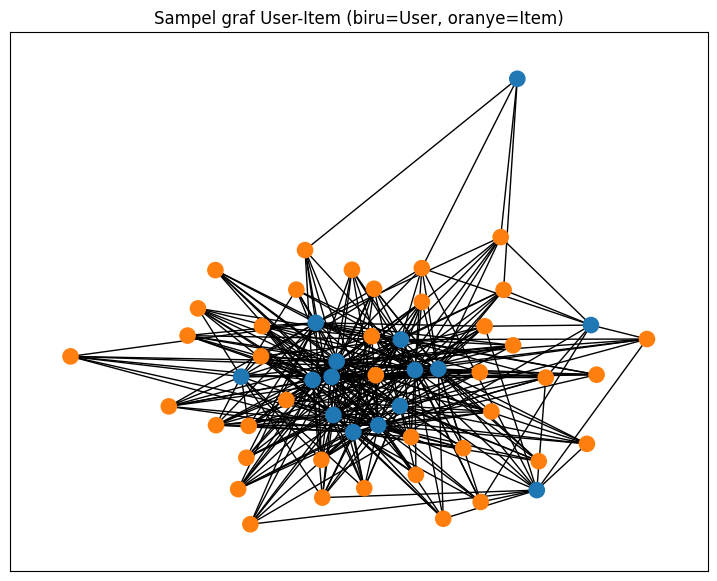

In [ ]:
#4.1 plot network
top_users = agg.groupby("visitorid").size().sort_values(ascending=False).head(15).index
sub = agg[agg["visitorid"].isin(top_users)]
# batasi item agar plot terbaca
sub = sub[sub["itemid"].isin(sub["itemid"].value_counts().head(40).index)]
G = nx.Graph()
for r in sub.itertuples():
    G.add_edge(f"U{r.visitorid}", f"I{r.itemid}", weight=r.w)
warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes]
plt.figure(figsize=(9, 7))
nx.draw_networkx(G, node_color=warna, node_size=120, font_size=6, with_labels=False)
plt.title("Sampel graf User-Item (biru=User, oranye=Item)")
plt.show()

In [34]:
print("Baris sub:", len(sub), "| Node:", G.number_of_nodes(), "| Edge:", G.number_of_edges())

Baris sub: 108 | Node: 6 | Edge: 5


Node: 55 | Edge: 332


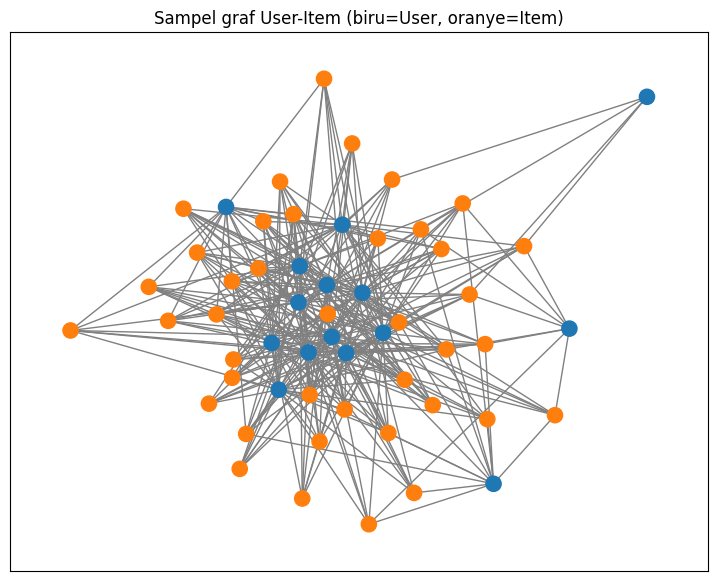

In [36]:
#4.1 plot network
import networkx as nx
import matplotlib.pyplot as plt

top_users = agg.groupby("visitorid").size().sort_values(ascending=False).head(15).index
sub = agg[agg["visitorid"].isin(top_users)]
sub = sub[sub["itemid"].isin(sub["itemid"].value_counts().head(40).index)]

G_user = nx.Graph()
for r in sub.itertuples():
    G_user.add_edge(f"U{r.visitorid}", f"I{r.itemid}", weight=r.w)

warna_user = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G_user.nodes]
print("Node:", G_user.number_of_nodes(), "| Edge:", G_user.number_of_edges())

fig = plt.figure(figsize=(9, 7), facecolor="white")
ax = fig.add_subplot(111)
nx.draw_networkx(G_user, ax=ax, node_color=warna_user, node_size=120,
                 with_labels=False, edge_color="gray")
ax.set_title("Sampel graf User-Item (biru=User, oranye=Item)")
fig.savefig("plot_user_item.png", dpi=150, facecolor="white")   # sebelum show
plt.show()

In [14]:
#5. VSM simpul Item
#5.1 matriks item x User
X_item = X_user.T.tocsr()   # (item x user)
print("Shape (item x user):", X_item.shape)
print("Dimensi vektor item (jumlah user):", X_item.shape[1])
print("Entri non-nol:", X_item.nnz)
print("Density:", X_item.nnz / (X_item.shape[0] * X_item.shape[1]))
nnz_per_item = np.diff(X_item.indptr)
print("User per item -> rata-rata:", nnz_per_item.mean(),
      "| median:", np.median(nnz_per_item), "| maks:", nnz_per_item.max())
print("Item dengan >= 2 user:", (nnz_per_item >= 2).sum(), "dari", len(nnz_per_item))
print("User dengan >= 2 item:", (np.diff(X_user.indptr) >= 2).sum(), "dari", X_user.shape[0])

Shape (item x user): (145405, 479153)
Dimensi vektor item (jumlah user): 479153
Entri non-nol: 726123
Density: 1.0422133717162307e-05
User per item -> rata-rata: 4.9937966369794715 | median: 2.0 | maks: 1068
Item dengan >= 2 user: 80538 dari 145405
User dengan >= 2 item: 96353 dari 479153


Isi: rata-rata 4,99 user per item, median 2, maksimum 1.068. Klaim “item punya lebih banyak irisan” benar: 55,4% item punya ≥2 user, sedangkan hanya 20,1% user punya ≥2 item

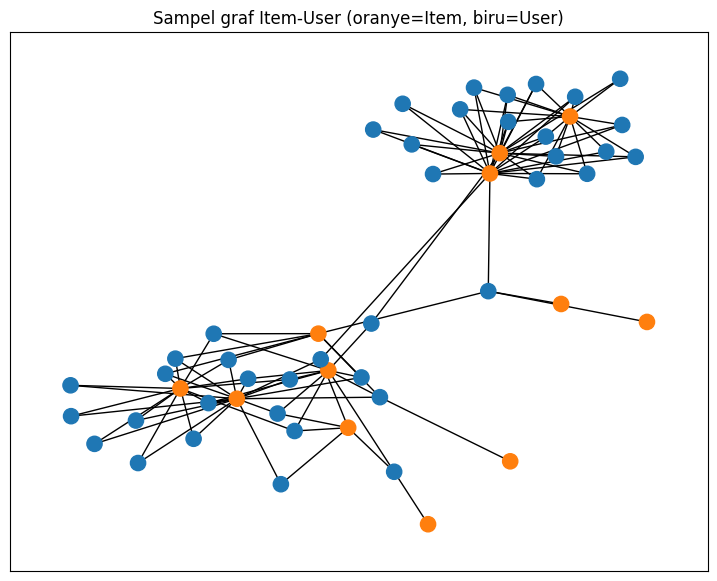

In [15]:
#5.2 plot networkx
top_items = agg.groupby("itemid").size().sort_values(ascending=False).head(15).index
sub = agg[agg["itemid"].isin(top_items)]
sub = sub[sub["visitorid"].isin(sub["visitorid"].value_counts().head(40).index)]

G = nx.Graph()
for r in sub.itertuples():
    G.add_edge(f"I{r.itemid}", f"U{r.visitorid}", weight=r.w)

warna = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G.nodes]
plt.figure(figsize=(9, 7))
nx.draw_networkx(G, node_color=warna, node_size=120, with_labels=False)
plt.title("Sampel graf Item-User (oranye=Item, biru=User)")
plt.savefig("plot_item_user.png", dpi=150)
plt.show()

# Karakteristik VSM Item
- Setiap Item dipetakan menjadi vektor berdimensi 479.153 (satu dimensi per User).
- Shape = (145.405, 479.153), transpos dari matriks User x Item; non-nol dan
  density sama persis (726.123; 1,04e-5).
- Rata-rata ... user per item (median ...; maks ...).
- Item cenderung punya lebih banyak irisan dibanding user, karena item populer
  dilihat banyak user, sedangkan kebanyakan user hanya menyentuh 1 item.
- Plot: sampel 15 item terpopuler dan 40 user teraktif; graf bipartit.

In [ ]:
#6. compare proyeksi
k = np.diff(X_user.indptr).astype(np.int64)   # item per user
d = np.diff(X_item.indptr).astype(np.int64)   # user per item

# batas atas jumlah edge proyeksi (sebelum menghapus pasangan duplikat)
edge_item_item = (k * (k - 1) // 2).sum()   # tiap user menghubungkan semua pasangan itemnya
edge_user_user = (d * (d - 1) // 2).sum()   # tiap item menghubungkan semua pasangan usernya

B = (X_user > 0).tocsr()
item_terhubung = int((B[k >= 2].sum(axis=0).A1 > 0).sum())   # item yang punya tetangga
user_terhubung = int((B[:, d >= 2].sum(axis=1).A1 > 0).sum())  # user yang punya tetangga

n_user, n_item = X_user.shape
hasil = pd.DataFrame({
    "Proyeksi": ["Item-Item", "User-User"],
    "Jumlah node": [n_item, n_user],
    "Node punya tetangga": [item_terhubung, user_terhubung],
    "Edge (batas atas)": [edge_item_item, edge_user_user],
})
hasil["% node terhubung"] = (hasil["Node punya tetangga"] / hasil["Jumlah node"] * 100).round(1)
hasil["Density (batas atas)"] = hasil["Edge (batas atas)"] / (hasil["Jumlah node"] * (hasil["Jumlah node"] - 1) / 2)
print(hasil.to_string())
print("Item dengan >= 2 user:", (d >= 2).sum(), "| User dengan >= 2 item:", (k >= 2).sum())
print("Maks user per item:", d.max(), "| Maks item per user:", k.max())

    Proyeksi  Jumlah node  Node punya tetangga  Edge (batas atas)  % node terhubung  Density (batas atas)
0  Item-Item       145405                84823            7028367              58.3              0.000665
1  User-User       479153               436657           12901302              91.1              0.000112
Item dengan >= 2 user: 80538 | User dengan >= 2 item: 96353
Maks user per item: 1068 | Maks item per user: 1201


# Perbandingan proyeksi
proyeksi Item-Item dipilih.
- Efisiensi: node 3,3x lebih sedikit dan edge 1,8x lebih sedikit, sehingga matriks similarity jauh lebih kecil.
- Kepadatan: 5,9x lebih padat, sehingga tiap edge lebih informatif.
- Trade-off: cakupan Item-Item 58,3% vs User-User 91,1%. Cakupan User-User tinggi karena terdongkrak item populer (maks 1.068 user per item), dan menghasilkan ratusan ribu edge dari satu item.
- Item-Item cocok untuk tujuan akhir (rekomendasi item) dan lebih stabil karena median item per user hanya 1.

In [ ]:
#7.Similarity item (Python)
B_item = (X_item > 0).astype(np.float32).tocsr()
Bn = normalize(B_item)                       
deg = np.diff(B_item.indptr)                 
item_ids = items.cat.categories
rng = np.random.default_rng(42)
kandidat = np.where((deg >= 20) & (deg <= 100))[0]
ref_idx = int(rng.choice(kandidat))
REF_ITEM = int(item_ids[ref_idx])
print("Item acuan:", REF_ITEM, "| user yang menyentuh:", deg[ref_idx])
sims = (Bn @ Bn[ref_idx].T).toarray().ravel()
sims[ref_idx] = 0
urut = np.lexsort((item_ids.values, -sims))[:5]   
df_top = pd.DataFrame({"itemId": item_ids[urut].astype(int), "similarity": sims[urut].round(4)})
print(df_top)

Item acuan: 44053 | user yang menyentuh: 43
   itemId  similarity
0  374821      0.3458
1    3621      0.1525
2    4422      0.1525
3    9276      0.1525
4    9934      0.1525


   visitor  relasi   item
0   409324  VIEWED  44053
1  1301071  VIEWED  44053
2   592214  VIEWED  44053
3    86872  VIEWED  44053
4   123900  VIEWED  44053


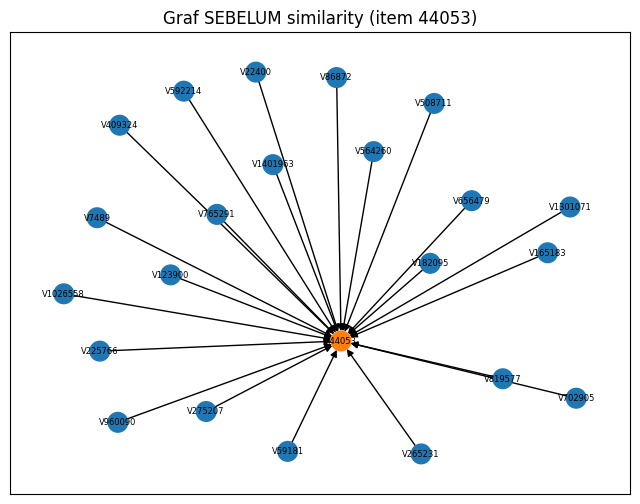

In [ ]:
#8.Graf SEBELUM similarity
import networkx as nx
import matplotlib.pyplot as plt

rows = run("""
MATCH (v:Visitor)-[r]->(i:Item {itemId: 44053})
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item
LIMIT 25
""")
print(pd.DataFrame(rows).head())

G = nx.DiGraph()
for r in rows:
    G.add_edge(f"V{r['visitor']}", f"I{r['item']}", label=r["relasi"])

warna = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G.nodes]
plt.figure(figsize=(8, 6))
nx.draw_networkx(G, node_color=warna, node_size=200, font_size=6)
plt.title("Graf SEBELUM similarity (item 44053)")
plt.savefig("graf_sebelum.png", dpi=150)
plt.show()

In [ ]:
#7a. Cypher 5 item paling mirip
REF_ITEM = 44053

q_top5 = """
MATCH (i:Item {itemId: $ref})<-[]-(v:Visitor)
WITH i, collect(DISTINCT v) AS vs
WITH i, vs, size(vs) AS di
UNWIND vs AS v
MATCH (v)-[]->(j:Item) WHERE j <> i
WITH i, di, j, count(DISTINCT v) AS common
MATCH (j)<-[]-(b:Visitor)
WITH i, di, j, common, count(DISTINCT b) AS dj
RETURN j.itemId AS itemId, common,
       toFloat(common) / sqrt(toFloat(di) * dj) AS similarity
ORDER BY similarity DESC, itemId ASC
LIMIT 5
"""
hasil_cypher = pd.DataFrame(run(q_top5, ref=REF_ITEM))
print(hasil_cypher)

   itemId  common  similarity
0  374821       6    0.345834
1    3621       1    0.152499
2    4422       1    0.152499
3    9276       1    0.152499
4    9934       1    0.152499


In [ ]:
#7b  Tulis similarity ke graf
rows = hasil_cypher[["itemId", "similarity"]].to_dict("records")

run("""
UNWIND $rows AS row
MATCH (i:Item {itemId: $ref}), (j:Item {itemId: row.itemId})
MERGE (i)-[s:SIMILAR_TO]->(j)
SET s.score = row.similarity, s.metode = 'cosine_biner_item_item'
""", ref=REF_ITEM, rows=rows)
hasil_7b = pd.DataFrame(run("""
MATCH (i:Item {itemId: $ref})-[s:SIMILAR_TO]->(j:Item)
RETURN i.itemId AS acuan, j.itemId AS mirip, s.score AS similarity
ORDER BY similarity DESC
""", ref=REF_ITEM))
print(hasil_7b)

   acuan   mirip  similarity
0  44053  374821    0.345834
1  44053    3621    0.152499
2  44053    4422    0.152499
3  44053    9276    0.152499
4  44053    9934    0.152499


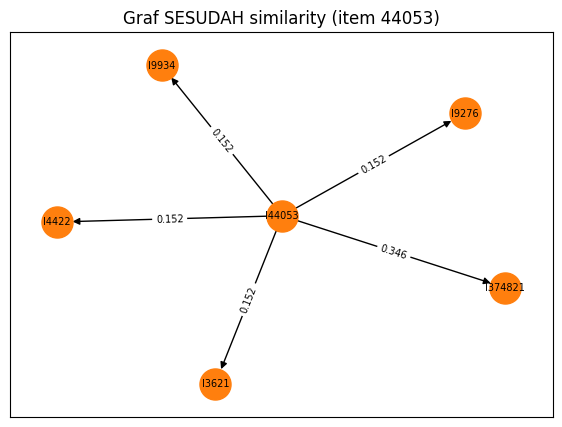

In [ ]:
#8. Graf SESUDAH similarity
G = nx.DiGraph()
for r in hasil_7b.itertuples():
    G.add_edge(f"I{r.acuan}", f"I{r.mirip}", w=round(r.similarity, 3))

pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(7, 5))
nx.draw_networkx(G, pos, node_color="tab:orange", node_size=500, font_size=7)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "w"), font_size=7)
plt.title("Graf SESUDAH similarity (item 44053)")
plt.savefig("graf_sesudah.png", dpi=150)
plt.show()

# analisis no 7 dan 8
No. 7b 
Lima item paling mirip dengan item 44053 ditulis sebagai relasi
`(:Item)-[:SIMILAR_TO {score}]->(:Item)`. `MERGE` dipakai agar relasi tidak ganda.
No. 8 Sebelum dan sesudah
- Sebelum: hanya relasi Visitor-[:VIEWED/ADDED_TO_CART/BOUGHT]->Item.
  Cypher: `MATCH (v:Visitor)-[r]->(i:Item {itemId: 44053}) RETURN v, r, i LIMIT 25`
- Sesudah: muncul relasi Item-[:SIMILAR_TO {score}]->Item.
  Cypher: `MATCH p=(i:Item {itemId: 44053})-[s:SIMILAR_TO]->(j:Item) RETURN p`

In [32]:
print("Item 5790 ada di graf P1?", 5790 in item_pos)

# bonus: berapa persen ground truth seluruh kandidat yang ada di P1
semua_truth = set().union(*[truth_by_user[u] - riwayat(u) for u in kandidat])
ada = [i for i in semua_truth if i in item_pos]
print(len(ada), "dari", len(semua_truth), "item ground truth ada di graf P1")

Item 5790 ada di graf P1? True
1179 dari 1310 item ground truth ada di graf P1


# NO 2.2 user acak seed=42
### Kesimpulan 2.2
- User acak (seed 42) adalah 125589. Riwayat P1: 174538, 257748, 303715.
  Ground truth P2: item 5790. Tiga item iklan: 51822, 74708, 393506.
- Hasil user terpilih: Hit@5 = 0, NDCG@5 = 0, Hit@3 = 0.
- Rata-rata pada 258 user kandidat: Hit@5 = 0,0155 (sekitar 4 user) dan NDCG@5 = 0,006.
- Akurasi rendah itu wajar untuk RetailRocket. Datanya sparse
  (median 1 item per user), riwayat user pendek, dan jeda P1 ke P2 sekitar 10 hari.
- Penyebab meleset pada user ini: item 5790 ada di P1 tetapi tidak termasuk 5 tetangga terdekat dari riwayat user.
- Keterbatasan: banyak skor rekomendasi sama (0,343) karena riwayat hanya 3 item,
  sehingga urutan ditentukan tie-break itemId.
- Perbaikan yang mungkin: menambahkan rekomendasi item populer atau
  mempertimbangkan kategori item (category_tree).

In [25]:
#1
from sklearn.preprocessing import normalize

p2 = pd.read_csv("data/events_p2.csv")
user_ids = users.cat.categories
item_ids = items.cat.categories
user_pos = {u: i for i, u in enumerate(user_ids)}
item_pos = {it: i for i, it in enumerate(item_ids)}

Bn = normalize((X_item > 0).astype(np.float32).tocsr())   # item x user, norma L2 = 1
k_hist = np.diff(X_user.indptr)

# ground truth: addtocart/transaction di P2
p2_beli = p2[p2["event"].isin(["addtocart", "transaction"])]
truth_by_user = p2_beli.groupby("visitorid")["itemid"].apply(set)

def riwayat(u):
    return set(item_ids[X_user[user_pos[u]].indices])

kandidat = []
for u, truth in truth_by_user.items():
    if u in user_pos and k_hist[user_pos[u]] >= 3 and (truth - riwayat(u)):
        kandidat.append(int(u))
kandidat = sorted(kandidat)

rng = np.random.default_rng(42)          # reproducible
USER = int(rng.choice(kandidat))
print("Kandidat user:", len(kandidat), "| User terpilih:", USER)
print("Riwayat P1:", sorted(riwayat(USER)))
print("Ground truth P2:", sorted(truth_by_user[USER] - riwayat(USER)))

Kandidat user: 258 | User terpilih: 125589
Riwayat P1: [174538, 257748, 303715]
Ground truth P2: [5790]


In [26]:
#2. knn item-based
def recommend(u, k=5, n=5):
    ui = user_pos[u]
    row = X_user[ui]
    seen = set(row.indices)
    skor = {}
    for idx, w in zip(row.indices, row.data):
        s = (Bn @ Bn[idx].T).toarray().ravel()
        s[idx] = 0
        nn = np.argpartition(-s, k)[:k]           # k tetangga terdekat
        for j in nn:
            if s[j] > 0 and j not in seen:
                skor[j] = skor.get(j, 0) + w * s[j]
    urut = sorted(skor.items(), key=lambda x: (-x[1], int(item_ids[x[0]])))[:n]
    return [(int(item_ids[j]), round(float(v), 4)) for j, v in urut]

rekom = recommend(USER, k=5, n=5)
df_rekom = pd.DataFrame(rekom, columns=["itemId", "skor"])
print(df_rekom)

   itemId   skor
0   51822  0.343
1   74708  0.343
2  393506  0.343
3  432682  0.343
4  466454  0.343


In [27]:
#3. item iklan
print("3 item yang diiklankan (k=5):", [i for i, _ in rekom[:3]])

3 item yang diiklankan (k=5): [51822, 74708, 393506]


In [28]:
#4. Hit@5 dan NDCG@5
def hit_at(rec, truth, n):
    return int(any(i in truth for i in rec[:n]))

def ndcg_at(rec, truth, n):
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:n]) if i in truth)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(truth), n)))
    return dcg / idcg if idcg > 0 else 0.0

truth = set(truth_by_user[USER]) - riwayat(USER)
rec_ids = [i for i, _ in rekom]

print("Rekomendasi:", rec_ids)
print("Ground truth:", sorted(truth))
print("Hit@5  :", hit_at(rec_ids, truth, 5))
print("NDCG@5 :", round(ndcg_at(rec_ids, truth, 5), 4))
print("Hit@3  :", hit_at(rec_ids, truth, 3))

Rekomendasi: [51822, 74708, 393506, 432682, 466454]
Ground truth: [5790]
Hit@5  : 0
NDCG@5 : 0.0
Hit@3  : 0


Hit@5 = 1 jika minimal satu dari 5 rekomendasi ada di ground truth, selain itu 0.
NDCG@5 = DCG / IDCG, dengan DCG = Σ rel_i / log2(i+1) untuk posisi i = 1..5, dan IDCG adalah DCG ideal (semua item benar di posisi teratas).

In [30]:
#5
print("Jumlah kandidat:", len(kandidat))
n_sampel = min(300, len(kandidat))          
rng2 = np.random.default_rng(123)         
sampel = rng2.choice(kandidat, size=n_sampel, replace=False)
H, N = [], []
for u in sampel:
    t = set(truth_by_user[u]) - riwayat(u)
    r = [i for i, _ in recommend(int(u), k=5, n=5)]
    H.append(hit_at(r, t, 5))
    N.append(ndcg_at(r, t, 5))

print("Ukuran sampel:", n_sampel)
print("Rata-rata Hit@5:", round(np.mean(H), 4), "| NDCG@5:", round(np.mean(N), 4))

Jumlah kandidat: 258
Ukuran sampel: 258
Rata-rata Hit@5: 0.0155 | NDCG@5: 0.006


In [37]:
for d in ["2015-05-12", "2015-06-26", "2015-07-06", "2015-08-10"]:
    print(d, int(pd.Timestamp(d).timestamp() * 1000))

2015-05-12 1431388800000
2015-06-26 1435276800000
2015-07-06 1436140800000
2015-08-10 1439164800000
